In [1]:
# ============================================================
# FINAL COMPARISON (RCNN vs YOLO)
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

print("="*60)
print("LOADING RESULTS...")
print("="*60)

# ---------------- PATHS ----------------
RCNN_DIR = "/kaggle/input/notebooks/anuragnayak11/notebook1-rcnn/outputs/rcnn"
YOLO_DIR = "/kaggle/input/notebooks/anusir/notebook2-yolo/outputs/yolo"

# ---------------- LOAD ----------------
rcnn_metrics = pd.read_csv(f"{RCNN_DIR}/metrics.csv")
yolo_metrics = pd.read_csv(f"{YOLO_DIR}/metrics.csv")

rcnn_speed = pd.read_csv(f"{RCNN_DIR}/speed.csv")
yolo_speed = pd.read_csv(f"{YOLO_DIR}/speed.csv")

LOADING RESULTS...


In [2]:
# ---------------- EXTRACT VALUES ----------------
rcnn_map50 = rcnn_metrics["map50"].iloc[-1]
yolo_map50 = yolo_metrics["map50"].iloc[0]

rcnn_map5095 = rcnn_metrics["map5095"].iloc[-1]
yolo_map5095 = yolo_metrics["map5095"].iloc[0]

rcnn_fps = rcnn_speed["fps"][0]
yolo_fps = yolo_speed["fps"][0]

rcnn_latency = rcnn_speed["latency_ms"][0]
yolo_latency = yolo_speed["latency_ms"][0]

rcnn_time = rcnn_metrics["epoch_time_sec"].mean()
yolo_time = yolo_metrics["epoch_time_sec"][0]

print("\nRESULT SUMMARY:")
print(f"RCNN  -> mAP50: {rcnn_map50:.4f}, FPS: {rcnn_fps:.2f}")
print(f"YOLO  -> mAP50: {yolo_map50:.4f}, FPS: {yolo_fps:.2f}")



RESULT SUMMARY:
RCNN  -> mAP50: 0.6934, FPS: 5.81
YOLO  -> mAP50: 0.7459, FPS: 50.12


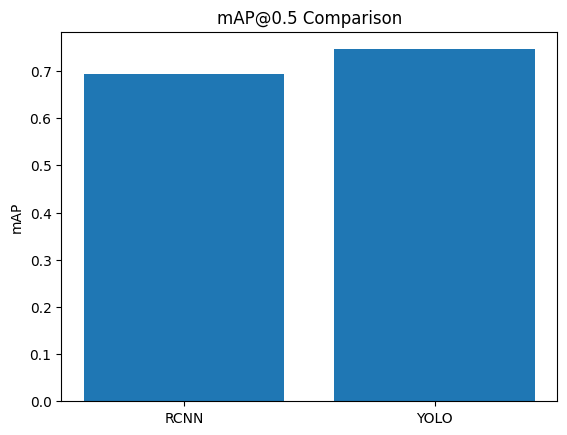

In [3]:
# ============================================================
# GRAPH 1: mAP@0.5
# ============================================================
plt.figure()
plt.bar(["RCNN", "YOLO"], [rcnn_map50, yolo_map50])
plt.title("mAP@0.5 Comparison")
plt.ylabel("mAP")
plt.savefig("comparison_map50.png")

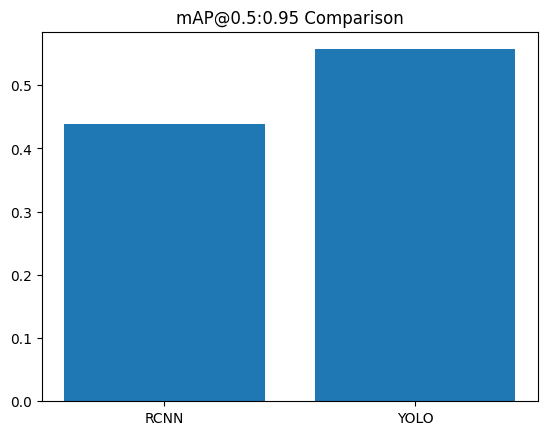

In [4]:
# ============================================================
# GRAPH 2: mAP@0.5:0.95
# ============================================================
plt.figure()
plt.bar(["RCNN", "YOLO"], [rcnn_map5095, yolo_map5095])
plt.title("mAP@0.5:0.95 Comparison")
plt.savefig("comparison_map5095.png")


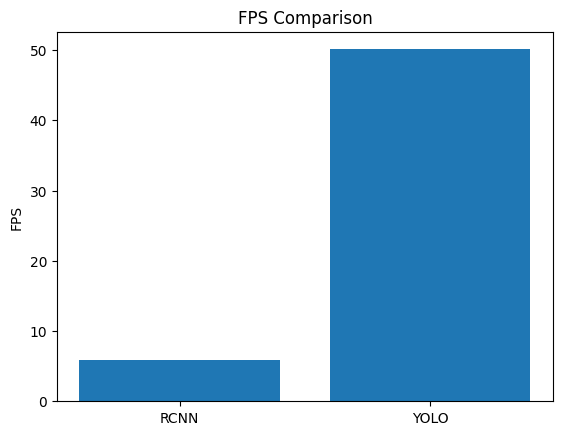

In [5]:
# ============================================================
# GRAPH 3: FPS
# ============================================================
plt.figure()
plt.bar(["RCNN", "YOLO"], [rcnn_fps, yolo_fps])
plt.title("FPS Comparison")
plt.ylabel("FPS")
plt.savefig("comparison_fps.png")

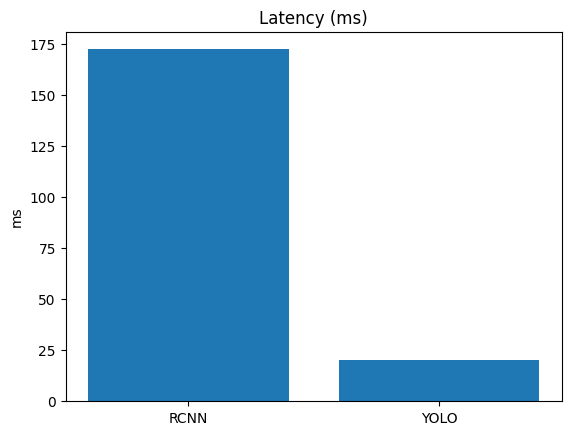

In [6]:
# ============================================================
# GRAPH 4: LATENCY
# ============================================================
plt.figure()
plt.bar(["RCNN", "YOLO"], [rcnn_latency, yolo_latency])
plt.title("Latency (ms)")
plt.ylabel("ms")
plt.savefig("comparison_latency.png")

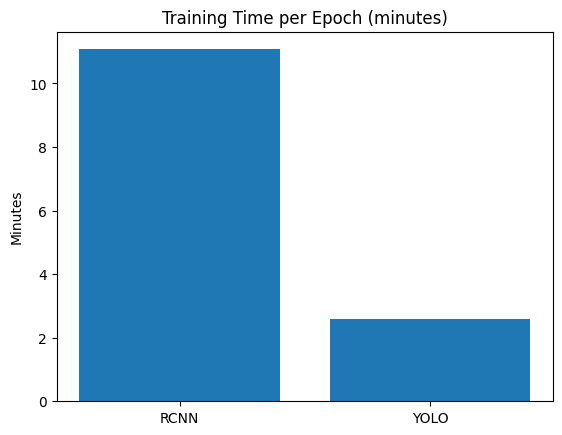

In [7]:
# ============================================================
# GRAPH 5: TRAINING TIME
# ============================================================
plt.figure()
plt.bar(["RCNN", "YOLO"], [rcnn_time/60, yolo_time/60])
plt.title("Training Time per Epoch (minutes)")
plt.ylabel("Minutes")
plt.savefig("comparison_training_time.png")

In [8]:

# ============================================================
# SAVE FINAL TABLE
# ============================================================
final_df = pd.DataFrame([
    {
        "Model": "RCNN",
        "mAP50": rcnn_map50,
        "mAP50-95": rcnn_map5095,
        "FPS": rcnn_fps,
        "Latency(ms)": rcnn_latency,
        "Epoch Time(min)": rcnn_time/60
    },
    {
        "Model": "YOLO",
        "mAP50": yolo_map50,
        "mAP50-95": yolo_map5095,
        "FPS": yolo_fps,
        "Latency(ms)": yolo_latency,
        "Epoch Time(min)": yolo_time/60
    }
])

final_df.to_csv("final_comparison.csv", index=False)
 

In [9]:

print("\nSaved:")
print(" - comparison_map50.png")
print(" - comparison_map5095.png")
print(" - comparison_fps.png")
print(" - comparison_latency.png")
print(" - comparison_training_time.png")
print(" - final_comparison.csv")

print("="*60)
print("COMPARISON COMPLETE")
print("="*60)


Saved:
 - comparison_map50.png
 - comparison_map5095.png
 - comparison_fps.png
 - comparison_latency.png
 - comparison_training_time.png
 - final_comparison.csv
COMPARISON COMPLETE
